# Prediction versus RAPID-modelled timing

Static, editable Matplotlib version of the hydrography-only RF scatter. **Run All** to display the PNG below. Change the settings in the first code cell or edit the plotting code directly, then rerun the plot cell.

Uses saved `geometry_normalized_9` predictions for the original cohort: 2,170 collapses × five held-out repeats. No model fitting or repeat averaging. The annotation reports mean scores across repeats. Negative shifts indicate advance; positive shifts indicate delay.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

# Works when launched from the repository root or RAPID/notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'RAPID/investigations/hydrography_rf_20261029').is_dir())
SOURCE = ROOT / 'RAPID/outputs/uncapped_event_window_20261020/hydrography_rf_compound_20261029'

# Edit these settings, then rerun the plot cell below.
FIGSIZE = (8.5, 8.2)
DPI = 200
POINT_SIZE = 9
POINT_ALPHA = 0.18
POINT_COLOR = '#243b53'
SIGNED_LOG = True  # False gives linear axes, still in minutes.
TITLE = 'Hydrography-only RF — predicted versus modelled timing'
PNG_PATH = SOURCE / 'figures/hydrography_rf_prediction_vs_modelled_notebook.png'


In [2]:
p = pd.read_parquet(SOURCE/'predictions.parquet')
p = p[p.model.eq('geometry_normalized_9') & p.cohort.eq('original')].copy()
assert len(p) == 2170*5 and not p.duplicated(['repeat','example','state']).any()
p['modelled_min'] = p.centroid_shift_hours*60
p['predicted_min'] = p.predicted_hours*60
s = pd.read_csv(SOURCE/'summary.csv')
s = s[s.model.eq('geometry_normalized_9') & s.cohort.eq('original')].iloc[0]


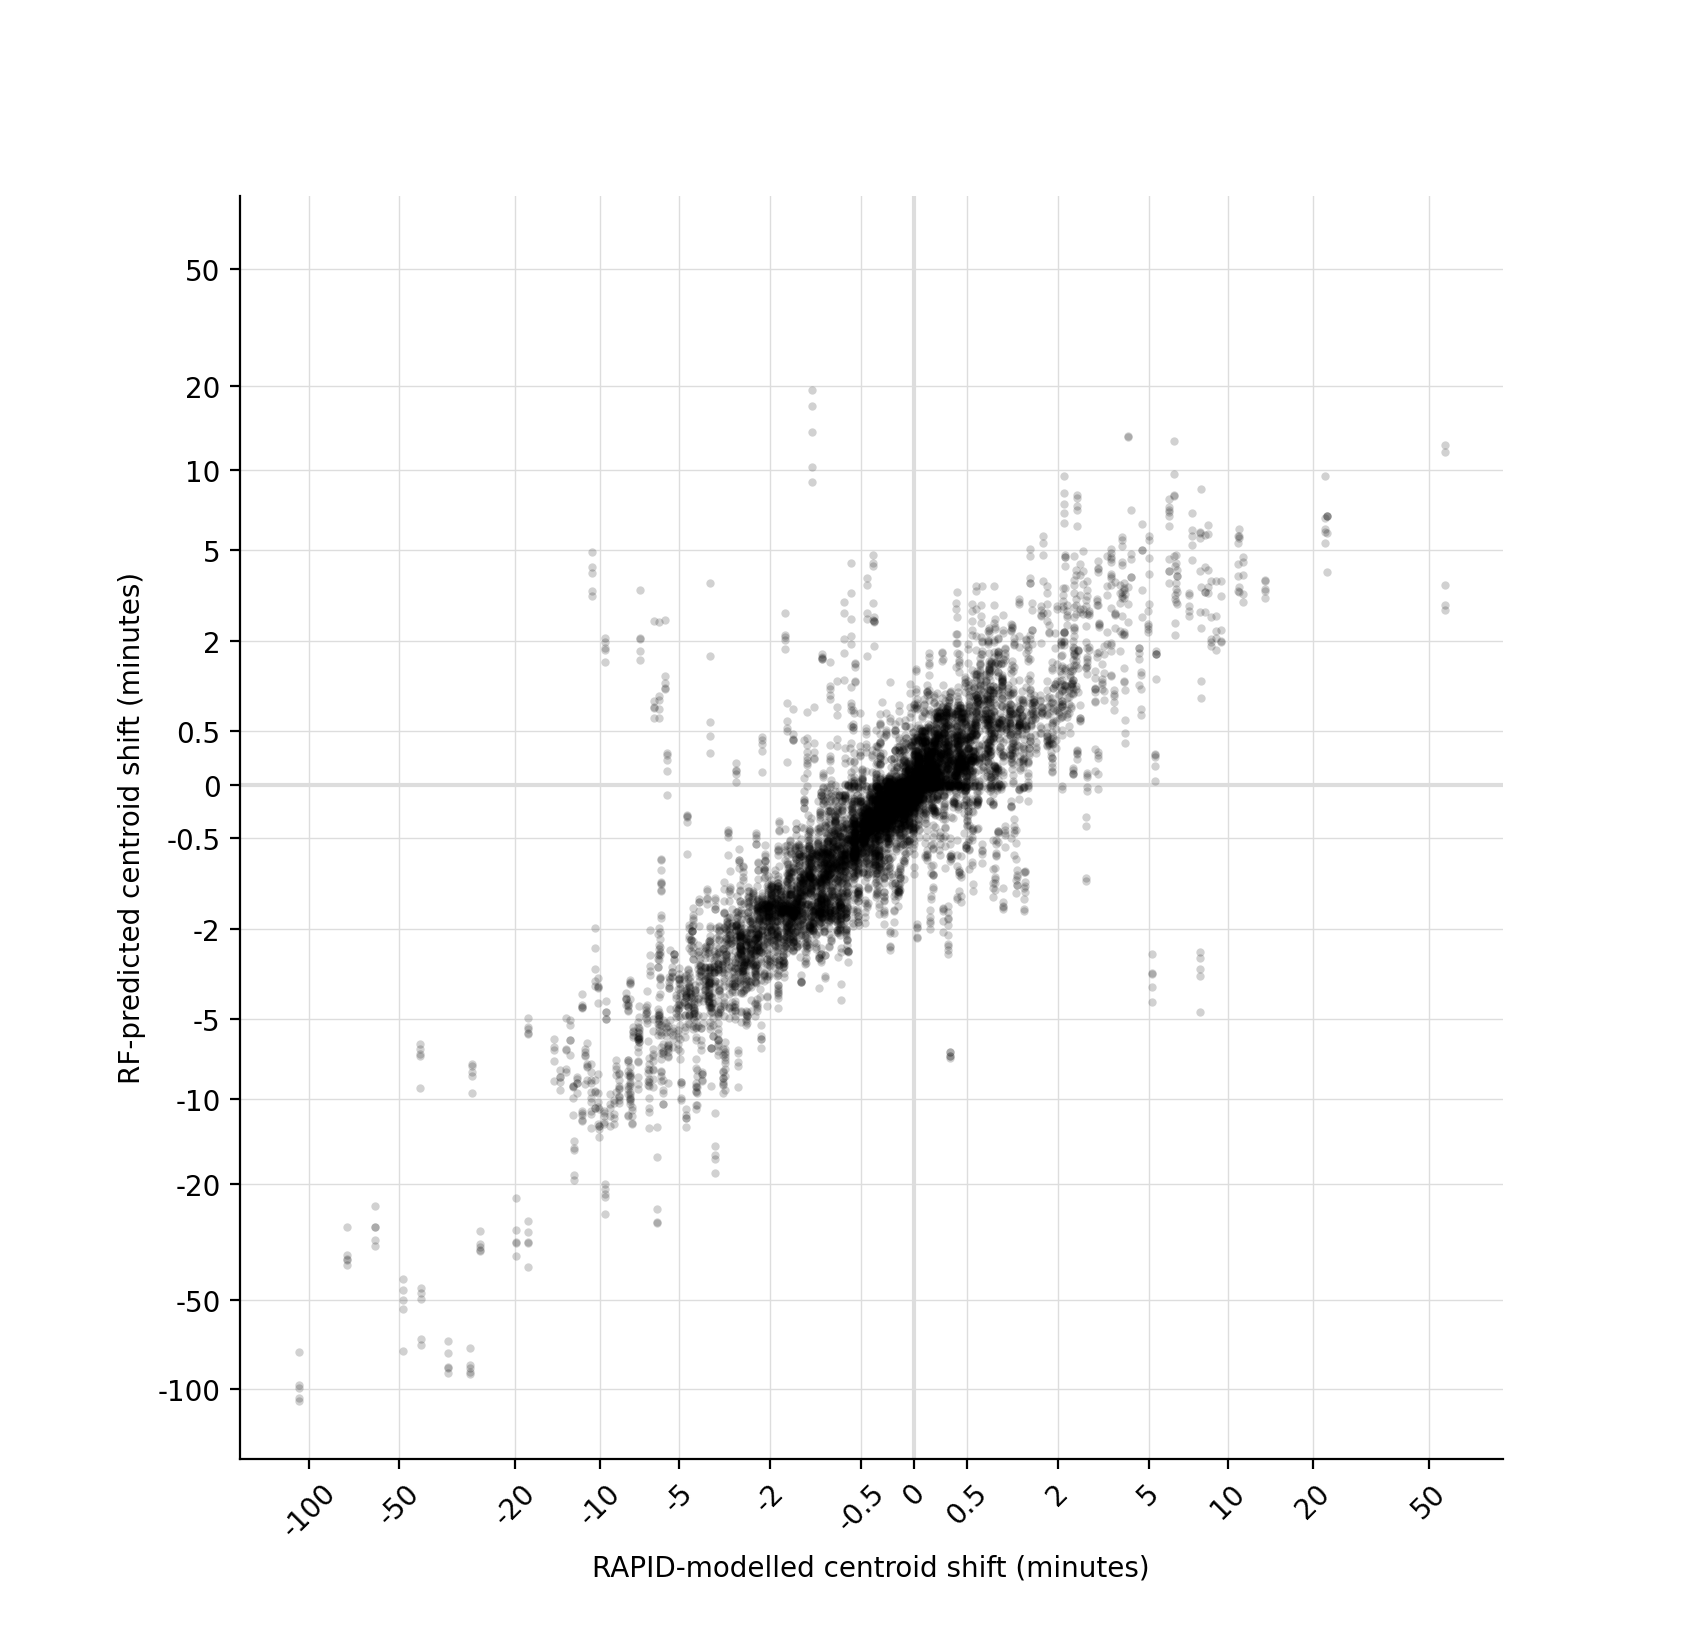

In [15]:
def transform(x):
    x = np.asarray(x)
    return np.sign(x)*np.log10(1+np.abs(x)) if SIGNED_LOG else x
x,y = transform(p.modelled_min),transform(p.predicted_min)
lo,hi = min(x.min(),y.min()),max(x.max(),y.max())
pad = (hi-lo)*.05
limits = (lo-pad,hi+pad)
ticks = np.array([-500,-200,-100,-50,-20,-10,-5,-2,-.5,0,.5,2,5,10,20,50,100,200,500])
ticks = ticks[(transform(ticks)>=limits[0]) & (transform(ticks)<=limits[1])]
fig,ax = plt.subplots(figsize=FIGSIZE)
ax.scatter(x,y,s=POINT_SIZE,c='black',alpha=POINT_ALPHA,linewidths=0,rasterized=True, zorder = 10)
# ax.plot(limits,limits,'--',color='black',lw=1.2,zorder=0)
ax.grid(True, color='#dddddd', linewidth=0.5, zorder = 0)

ax.axhline(0,color='#dddddd',lw=1.5,zorder=2, linestyle = '-');ax.axvline(0,color='#dddddd',lw=1.5,zorder=2)
ax.set(xlim=limits,ylim=limits,xlabel='RAPID-modelled centroid shift (minutes)',ylabel='RF-predicted centroid shift (minutes)')
ax.set_xticks(transform(ticks),[f'{t:g}' for t in ticks],rotation=45)
ax.set_yticks(transform(ticks),[f'{t:g}' for t in ticks])
ax.set_aspect('equal',adjustable='box')
ax.spines[['top','right']].set_visible(False)
# ax.text(.035,.96,f'Mean across 5 repeats\n$R^2$ = {s.r2_mean:.3f}\nMAE = {s.mae_minutes_mean*60:.1f} seconds',transform=ax.transAxes,va='top',fontsize=11,bbox=dict(facecolor='white',alpha=.92,edgecolor='none',pad=7))
# fig.suptitle(TITLE,fontsize=15,y=.97)
# ax.set_title('Normalized spread change + entropy change · grouped-compound validation',fontsize=10,pad=14)
# fig.text(.5,.035,'2,170 individual collapses; five held-out predictions per case (10,850 points).\n' + ('Signed-log' if SIGNED_LOG else 'Linear') + ' axes; labels show minutes. Negative = advance; positive = delay.\nFixed-Manning responses, finite 0.5% event window. Dashed line = perfect prediction.',ha='center',fontsize=9,color='#444444')
# fig.subplots_adjust(bottom=.21,top=.87,left=.13,right=.96)
# Render a plain PNG inline; no widget or dropdown renderer required.
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=DPI)
plt.close(fig)
display(Image(data=buffer.getvalue()))


## Optional PNG export
Run the following cell to save the edited figure to a separate PNG.

In [4]:
PNG_PATH.parent.mkdir(parents=True, exist_ok=True)
PNG_PATH.write_bytes(buffer.getvalue())
print(PNG_PATH)

/Users/6256481/Code/river-hierarchy/RAPID/outputs/uncapped_event_window_20261020/hydrography_rf_compound_20261029/figures/hydrography_rf_prediction_vs_modelled_notebook.png


## Six-input quadratic ridge — primary and secondary models (recorded 6 November 2026)

Predictors: **allocated mean route-length change, parent slope descriptor, log1p mean-width ratio, complexity change, ΔGₘ and entropy change**. Six inputs expand to 27 quadratic terms plus an intercept. This section uses saved held-out predictions; it does not refit models.

The default figure includes **2,170 ordinary units + 15 full-network controls**, with **equal weight per parent–child pair** in the reported scores. Training retained equal-river weights. Repeated validation predictions are all displayed; scores are computed on each complete out-of-fold repeat and then averaged. A signed-log display makes small advances/delays visible, but all scores are calculated from **untransformed minutes**. The dashed diagonal denotes perfect prediction.

Change `RIDGE_STRATEGY`, `RIDGE_POPULATION` or the appearance settings below, then rerun the following cells. The earlier nine-input RF figure remains above as a historical comparison. Ridge penalty sensitivity and final residual checks remain pending.


**Retained secondary model:** set `RIDGE_MODEL = 'secondary_area'` to replace only ΔGₘ with area change. The same six-input quadratic specification, training weights and validation splits apply. The secondary is a sensitivity model, not an equally performing alternative. Settings and rationale: [current model reference](../CURRENT_GEOMETRY_PREDICTION_MODELS.md); machine-readable record: [model settings](../config/geometry_prediction_models.json). Both use saved results, with no refitting.


In [1]:
from pathlib import Path
from io import BytesIO
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

RIDGE_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'RAPID/outputs/entropy_complexity_g_ridge_20261104').is_dir())
# Choose 'primary_G' or the retained no-ΔGₘ model 'secondary_area'.
RIDGE_MODEL = 'primary_G'
RIDGE_MODEL_SETTINGS = json.loads((RIDGE_ROOT / 'RAPID/config/geometry_prediction_models.json').read_text())
assert RIDGE_MODEL in RIDGE_MODEL_SETTINGS['models']
RIDGE_SPEC = RIDGE_MODEL_SETTINGS['models'][RIDGE_MODEL]
RIDGE_SOURCE = RIDGE_ROOT / RIDGE_SPEC['prediction_directory']
RIDGE_KGE_SOURCE = RIDGE_ROOT / RIDGE_SPEC['score_directory']
RIDGE_ESTIMATOR = RIDGE_SPEC['prediction_estimator']
RIDGE_MODEL_LABEL = RIDGE_SPEC['label']

# Choose: 'compound_mixed', 'leave_one_network_out', 'network_balanced'.
RIDGE_STRATEGY = 'compound_mixed'
# Choose: 'all', 'ordinary', 'full_network'.
RIDGE_POPULATION = 'all'
# 'equal_pair' is the agreed headline. 'equal_river' reproduces the earlier
# diagnostics; for 'all' it gives 50% to each cohort, equal rivers within cohort.
RIDGE_WEIGHTING = 'equal_pair'
RIDGE_SIGNED_LOG = True
RIDGE_FIGSIZE = (8.5, 8.2)
RIDGE_DPI = 200
RIDGE_POINT_SIZE = 9
RIDGE_POINT_ALPHA = 0.18
RIDGE_CONTROL_COLOR = '#2563eb'
RIDGE_SHOW_TITLE = True
RIDGE_SHOW_SCORES = True
RIDGE_SHOW_LEGEND = True
RIDGE_SHOW_IDENTITY = True
RIDGE_STRATEGY_LABELS = {
    'compound_mixed': 'Compound-family grouped',
    'leave_one_network_out': 'Leave one network out',
    'network_balanced': 'Network-grouped fivefold',
}
RIDGE_POPULATION_LABELS = {
    'all': 'All parent–child comparisons',
    'ordinary': 'Ordinary unit comparisons',
    'full_network': 'Full-network controls',
}
assert RIDGE_STRATEGY in RIDGE_STRATEGY_LABELS
assert RIDGE_POPULATION in RIDGE_POPULATION_LABELS
assert RIDGE_WEIGHTING in ['equal_pair', 'equal_river']
RIDGE_PNG_PATH = RIDGE_SOURCE / 'figures' / (
    f'six_input_ridge_{RIDGE_MODEL}_{RIDGE_STRATEGY}_{RIDGE_POPULATION}_{RIDGE_WEIGHTING}'
    f'_{"signed_log" if RIDGE_SIGNED_LOG else "linear"}.png'
)


In [2]:
ridge_all_predictions = pd.read_parquet(RIDGE_SOURCE / 'predictions.parquet')
ridge_predictions = ridge_all_predictions.loc[
    ridge_all_predictions.estimator.eq(RIDGE_ESTIMATOR)
    & ridge_all_predictions.strategy.eq(RIDGE_STRATEGY)
].copy()
if RIDGE_POPULATION != 'all':
    cohort = {'ordinary': 'original', 'full_network': 'segmented'}[RIDGE_POPULATION]
    ridge_predictions = ridge_predictions[ridge_predictions.cohort.eq(cohort)].copy()
assert not ridge_predictions.duplicated(['repeat', 'example', 'state']).any()
ridge_n_cases = {'all': 2185, 'ordinary': 2170, 'full_network': 15}[RIDGE_POPULATION]
assert ridge_predictions.groupby('repeat').size().eq(ridge_n_cases).all()
ridge_predictions['modelled_min'] = ridge_predictions.centroid_shift_hours * 60
ridge_predictions['predicted_min'] = ridge_predictions.predicted_hours * 60
assert np.isfinite(ridge_predictions[['modelled_min', 'predicted_min']]).all().all()

# Compute scores from raw minutes, not the signed-log display coordinates.
# KGE-2009 uses correlation, SD ratio and mean ratio; signed means near zero
# require caution. The saved component-level audit is in RIDGE_KGE_SOURCE.
def ridge_repeat_metrics(g):
    y = g.modelled_min.to_numpy(float)
    prediction = g.predicted_min.to_numpy(float)
    if RIDGE_WEIGHTING == 'equal_pair':
        w = np.ones(len(g))
    elif RIDGE_POPULATION == 'all':
        cohort_rivers = g.groupby('cohort').example.nunique()
        w = (1 / g.groupby(['cohort', 'example']).example.transform('size').to_numpy()
             / g.cohort.map(cohort_rivers).to_numpy())
    else:
        w = 1 / g.groupby('example').example.transform('size').to_numpy()
    w = w / w.sum()
    my, mp = w @ y, w @ prediction
    sy = np.sqrt(w @ ((y - my)**2))
    sp = np.sqrt(w @ ((prediction - mp)**2))
    r = np.clip(w @ ((y - my) * (prediction - mp)) / (sy * sp), -1, 1)
    kge = 1 - np.sqrt((r - 1)**2 + (sp / sy - 1)**2 + (mp / my - 1)**2)
    return {'R²': 1 - (w @ ((prediction - y)**2)) / sy**2,
            'KGE': kge, 'MAE (min)': w @ np.abs(prediction - y)}

ridge_repeat_scores = pd.DataFrame([
    {'repeat': repeat, **ridge_repeat_metrics(g)}
    for repeat, g in ridge_predictions.groupby('repeat')
])
ridge_scores = ridge_repeat_scores[['R²', 'KGE', 'MAE (min)']].mean()
ridge_repeats = len(ridge_repeat_scores)
# Confirm the displayed metrics reproduce the existing accepted score table.
ridge_saved = pd.read_csv(RIDGE_KGE_SOURCE / 'summary.csv')
ridge_saved = ridge_saved[
    ridge_saved.estimator.eq(RIDGE_ESTIMATOR)
    & ridge_saved.strategy.eq(RIDGE_STRATEGY)
    & ridge_saved.population.eq(RIDGE_POPULATION)
    & ridge_saved.weighting.eq(RIDGE_WEIGHTING)
]
assert len(ridge_saved) == 1
np.testing.assert_allclose(ridge_scores.to_numpy(),
    ridge_saved[['r2', 'kge', 'mae_minutes']].iloc[0].to_numpy(), atol=1e-12)
print(f'{RIDGE_MODEL_LABEL} — {ridge_n_cases:,} parent–child pairs; {ridge_repeats} held-out repeat(s); '
      f'{len(ridge_predictions):,} plotted predictions. Scoring: {RIDGE_WEIGHTING}.')
display(ridge_scores.round(3).to_frame('Six-input quadratic ridge'))


Primary: ΔGₘ — 2,185 parent–child pairs; 5 held-out repeat(s); 10,925 plotted predictions. Scoring: equal_pair.
           Six-input quadratic ridge
R²                             0.867
KGE                            0.837
MAE (min)                      0.940


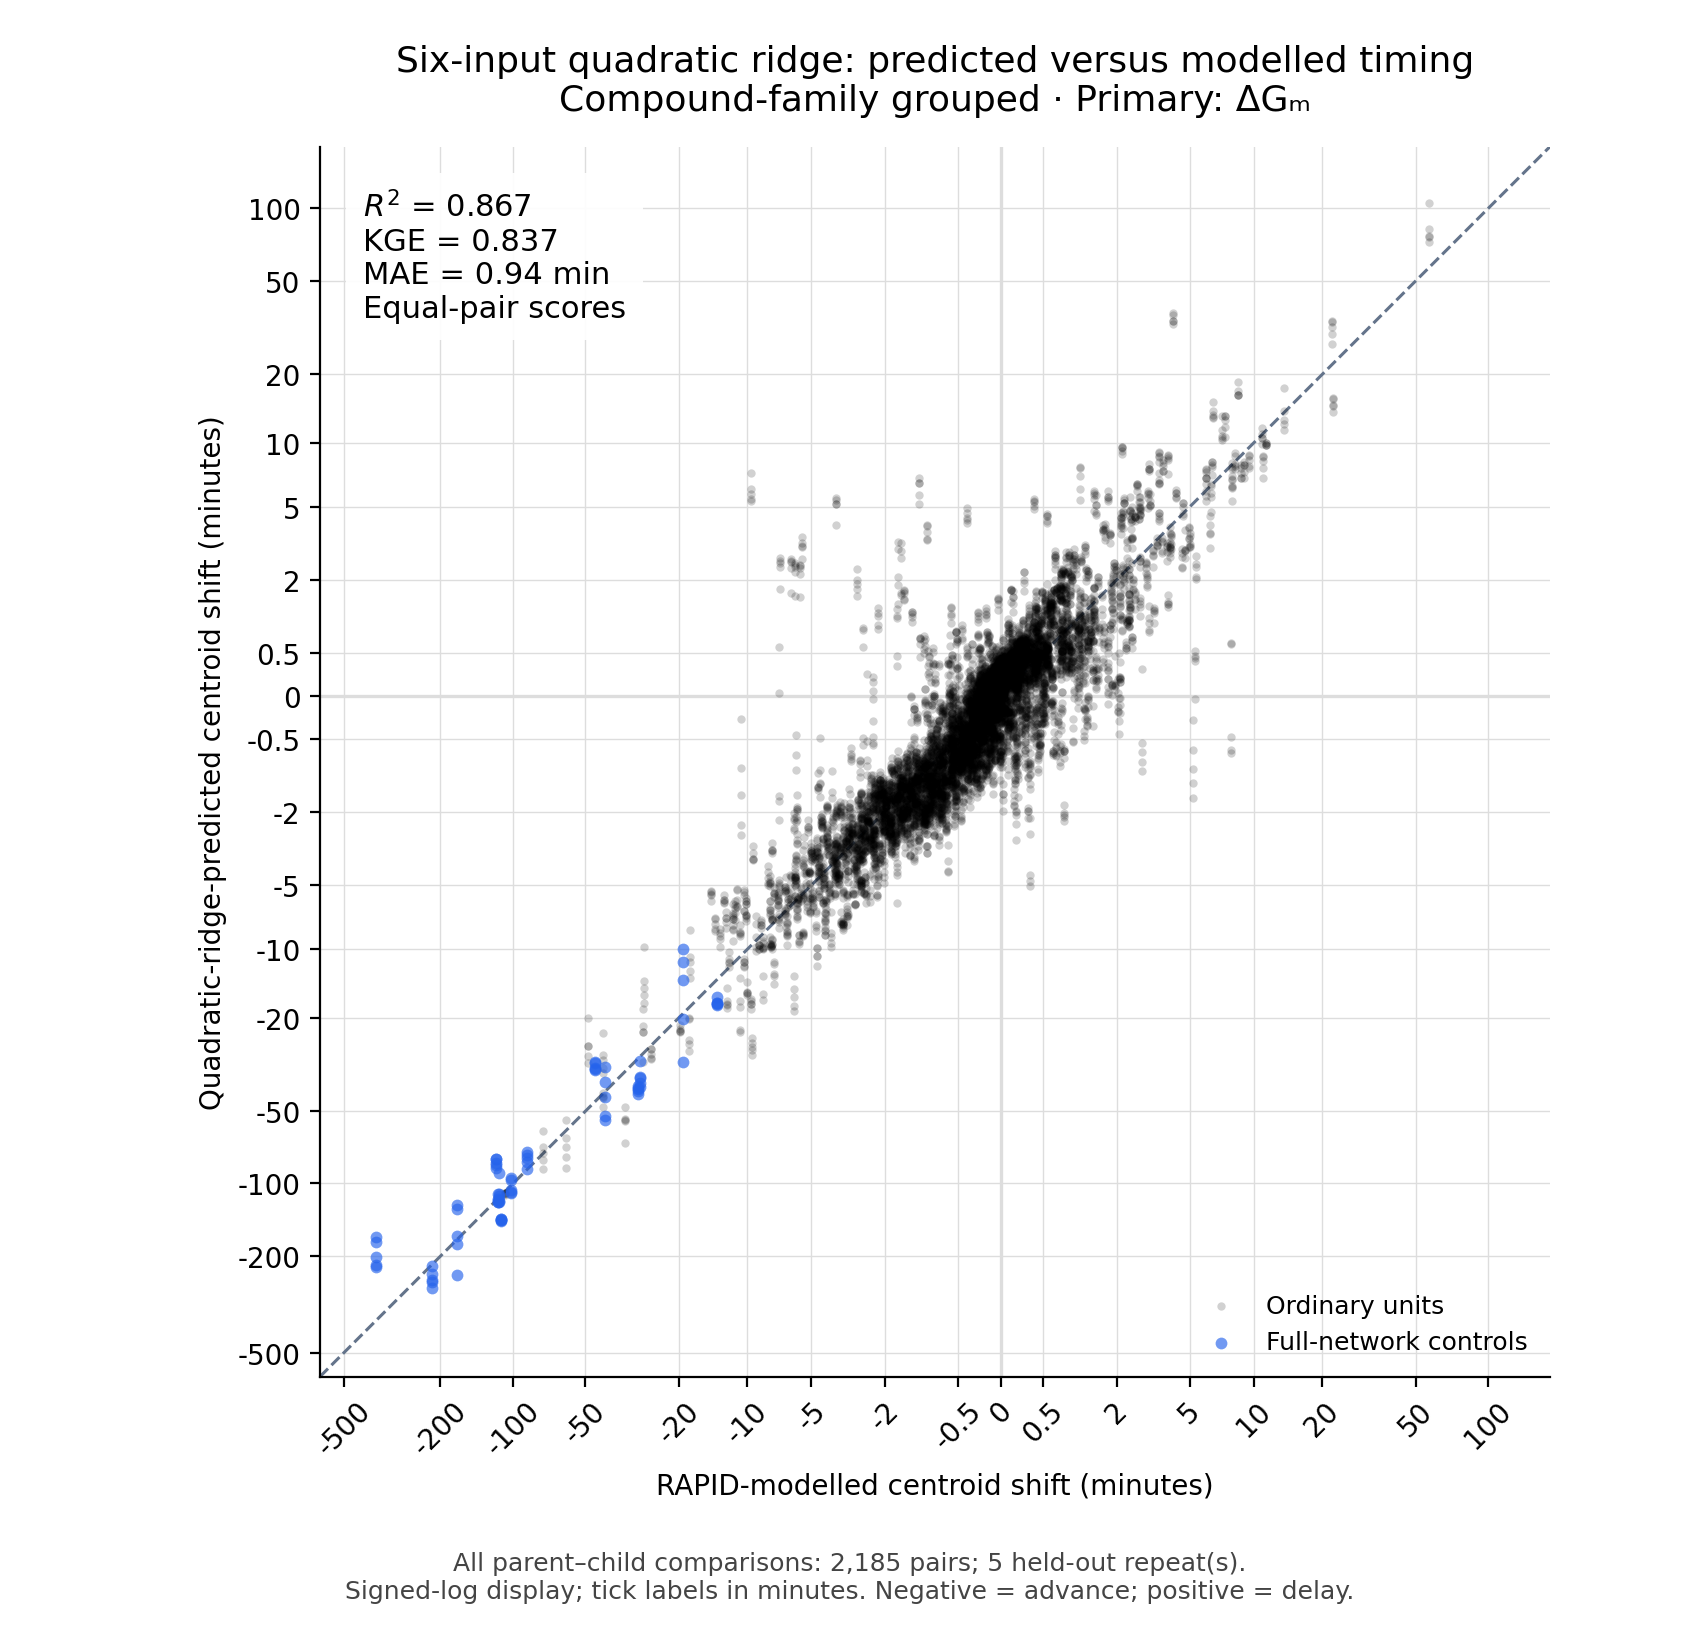

In [3]:
def ridge_transform(values):
    values = np.asarray(values, dtype=float)
    return np.sign(values) * np.log10(1 + np.abs(values)) if RIDGE_SIGNED_LOG else values

ridge_x = ridge_transform(ridge_predictions.modelled_min)
ridge_y = ridge_transform(ridge_predictions.predicted_min)
ridge_lo, ridge_hi = min(ridge_x.min(), ridge_y.min()), max(ridge_x.max(), ridge_y.max())
ridge_pad = (ridge_hi - ridge_lo) * 0.05
ridge_limits = (ridge_lo - ridge_pad, ridge_hi + ridge_pad)
ridge_ticks = np.array([-2000,-1000,-500,-200,-100,-50,-20,-10,-5,-2,-.5,
                        0,.5,2,5,10,20,50,100,200,500,1000,2000])
ridge_ticks = ridge_ticks[(ridge_transform(ridge_ticks) >= ridge_limits[0])
                          & (ridge_transform(ridge_ticks) <= ridge_limits[1])]
ridge_fig, ridge_ax = plt.subplots(figsize=RIDGE_FIGSIZE)
for cohort, label, color, size, alpha in [
    ('original', 'Ordinary units', 'black', RIDGE_POINT_SIZE, RIDGE_POINT_ALPHA),
    ('segmented', 'Full-network controls', RIDGE_CONTROL_COLOR, RIDGE_POINT_SIZE * 2, 0.65),
]:
    mask = ridge_predictions.cohort.eq(cohort).to_numpy()
    if mask.any():
        ridge_ax.scatter(ridge_x[mask], ridge_y[mask], s=size, c=color, alpha=alpha,
                         linewidths=0, rasterized=True, zorder=3, label=label)
if RIDGE_SHOW_IDENTITY:
    ridge_ax.plot(ridge_limits, ridge_limits, '--', color='#64748b', lw=1.1, zorder=2)
ridge_ax.grid(True, color='#dddddd', linewidth=.5, zorder=0)
ridge_ax.axhline(0, color='#dddddd', lw=1.2, zorder=1)
ridge_ax.axvline(0, color='#dddddd', lw=1.2, zorder=1)
ridge_ax.set(xlim=ridge_limits, ylim=ridge_limits,
             xlabel='RAPID-modelled centroid shift (minutes)',
             ylabel='Quadratic-ridge-predicted centroid shift (minutes)')
ridge_ax.set_xticks(ridge_transform(ridge_ticks), [f'{t:g}' for t in ridge_ticks], rotation=45)
ridge_ax.set_yticks(ridge_transform(ridge_ticks), [f'{t:g}' for t in ridge_ticks])
ridge_ax.set_aspect('equal', adjustable='box')
ridge_ax.spines[['top', 'right']].set_visible(False)
if RIDGE_SHOW_TITLE:
    ridge_ax.set_title('Six-input quadratic ridge: predicted versus modelled timing\n'
                       + RIDGE_STRATEGY_LABELS[RIDGE_STRATEGY] + ' · ' + RIDGE_MODEL_LABEL, fontsize=13, pad=13)
if RIDGE_SHOW_SCORES:
    ridge_annotation = (f'$R^2$ = {ridge_scores["R²"]:.3f}\n'
                        f'KGE = {ridge_scores["KGE"]:.3f}\n'
                        f'MAE = {ridge_scores["MAE (min)"]:.2f} min\n'
                        + ('Equal-pair scores' if RIDGE_WEIGHTING == 'equal_pair'
                           else 'Balanced-weight scores'))
    ridge_ax.text(.035, .965, ridge_annotation, transform=ridge_ax.transAxes,
                  va='top', fontsize=11,
                  bbox=dict(facecolor='white', alpha=.92, edgecolor='none', pad=6))
if RIDGE_SHOW_LEGEND:
    ridge_ax.legend(loc='lower right', fontsize=9, frameon=False)
ridge_caption = (f'{RIDGE_POPULATION_LABELS[RIDGE_POPULATION]}: {ridge_n_cases:,} pairs; '
                 f'{ridge_repeats} held-out repeat(s).\n'
                 + ('Signed-log display' if RIDGE_SIGNED_LOG else 'Linear display')
                 + '; tick labels in minutes. Negative = advance; positive = delay.')
ridge_fig.text(.5, .025, ridge_caption, ha='center', fontsize=9, color='#444444')
ridge_fig.subplots_adjust(bottom=.16, top=.91, left=.13, right=.97)
ridge_buffer = BytesIO()
ridge_fig.savefig(ridge_buffer, format='png', dpi=RIDGE_DPI)
plt.close(ridge_fig)
display(Image(data=ridge_buffer.getvalue()))


### Export the current ridge figure

The filename includes model, validation strategy, population, weighting and display scale. Change those settings and rerun the preceding cells to export another version. This does not overwrite the historical RF figure.


In [5]:
RIDGE_PNG_PATH.parent.mkdir(parents=True, exist_ok=True)
RIDGE_PNG_PATH.write_bytes(ridge_buffer.getvalue())
print(RIDGE_PNG_PATH)


/Users/6256481/Code/river-hierarchy/RAPID/outputs/entropy_complexity_g_ridge_20261104/figures/six_input_ridge_primary_G_compound_mixed_all_equal_pair_signed_log.png
